
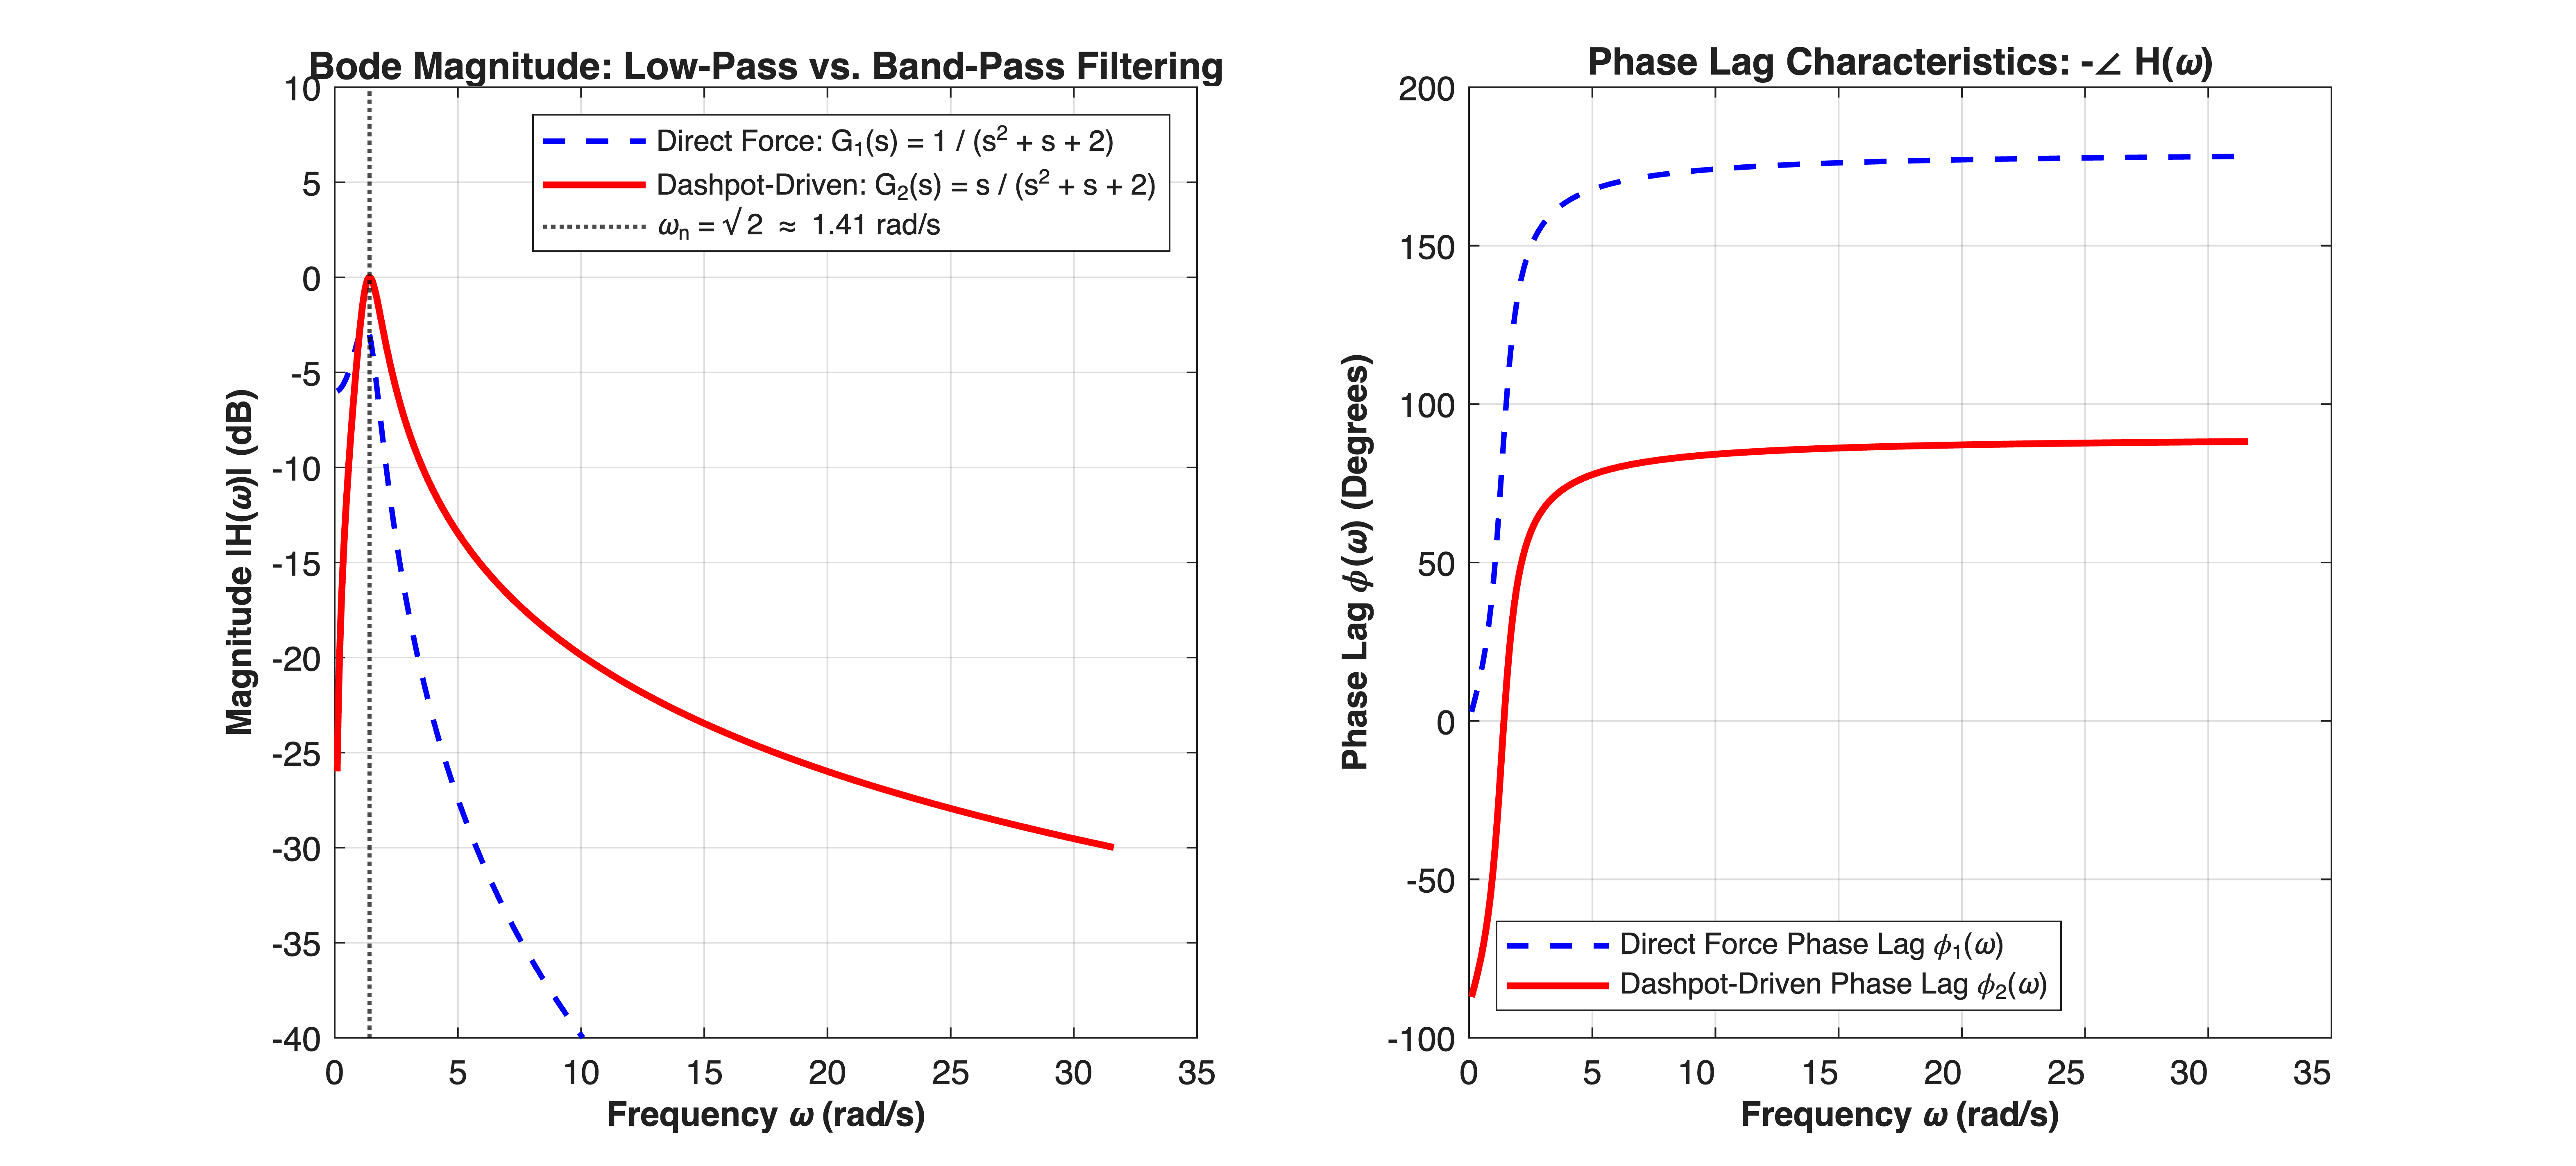

In [1]:
%% MIT 18.03 Lecture 14: Complex Gain, Phase Lag & Dashpot-Driven Dynamics
% Description: Analyzes frequency response and complex gain:
%              1) Bode magnitude/phase comparison: Direct Force vs. Dashpot Driving.
%              2) Time-domain tracking of dashpot-driven system mx'' + bx' + kx = b*y'.
%
% % Required Toolboxes:
% %   - Base MATLAB (Zero external dependency: complex arithmetic & ode45).
% % Optional Toolboxes:
% %   - Control System Toolbox (Equivalent to tf, bode, and lsim commands).
%
% % MBD Concept Mapping: Demonstrates complex gain H(w) = G(jw).
% %                      Dashpot input introduces a differentiator zero at origin: G(s) = bs/(ms^2 + bs + k),
% %                      yielding band-pass filtering behavior common in vibration isolation.


clear; clc; close all;


%% =========================================================================
%% Part 1: Frequency Response & Complex Gain Bode Analysis
%% =========================================================================
m = 1.0; b = 1.0; k = 2.0; % Baseline parameters from lecture
w_sweep = logspace(-1, 1.5, 600); % Frequency sweep from 0.1 to ~30 rad/s


% 1. Direct Forcing: mx'' + bx' + kx = F -> H1(w) = 1 / p(iw)
p_jw = -m * (w_sweep.^2) + 1i * b * w_sweep + k;
H_direct = 1 ./ p_jw;


% 2. Dashpot-Driven (Base Excitation): mx'' + bx' + kx = b*y' -> H2(w) = (b*i*w) / p(iw)
H_dashpot = (1i * b * w_sweep) ./ p_jw;


% Extract magnitudes (dB) and phase lags (deg)
mag_direct_dB  = 20 * log10(abs(H_direct));
phase_direct_deg = -angle(H_direct) * (180 / pi); % Phase lag phi


mag_dashpot_dB = 20 * log10(abs(H_dashpot));
phase_dashpot_deg = -angle(H_dashpot) * (180 / pi);


figure('Color', [1 1 1], 'Position', [100, 100, 1150, 520]);


% Subplot 1: Magnitude Response (Bode Magnitude)
subplot(1, 2, 1);
hold on; grid on; box on;
semilogx(w_sweep, mag_direct_dB, 'b--', 'LineWidth', 1.6, ...
    'DisplayName', 'Direct Force: G_1(s) = 1 / (s^2 + s + 2)');
semilogx(w_sweep, mag_dashpot_dB, 'r-', 'LineWidth', 2.0, ...
    'DisplayName', 'Dashpot-Driven: G_2(s) = s / (s^2 + s + 2)');


xline(sqrt(k/m), 'k:', 'LineWidth', 1.2, 'DisplayName', '\omega_n = \surd 2 \approx 1.41 rad/s');
xlabel('Frequency \omega (rad/s)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('Magnitude |H(\omega)| (dB)', 'FontSize', 10, 'FontWeight', 'bold');
title('Bode Magnitude: Low-Pass vs. Band-Pass Filtering', 'FontSize', 11, 'FontWeight', 'bold');
legend('Location', 'northeast', 'FontSize', 8.5);
ylim([-40, 10]);


% Subplot 2: Phase Lag Response (Bode Phase Lag)
subplot(1, 2, 2);
hold on; grid on; box on;
semilogx(w_sweep, phase_direct_deg, 'b--', 'LineWidth', 1.6, ...
    'DisplayName', 'Direct Force Phase Lag \phi_1(\omega)');
semilogx(w_sweep, phase_dashpot_deg, 'r-', 'LineWidth', 2.0, ...
    'DisplayName', 'Dashpot-Driven Phase Lag \phi_2(\omega)');


xlabel('Frequency \omega (rad/s)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('Phase Lag \phi(\omega) (Degrees)', 'FontSize', 10, 'FontWeight', 'bold');
title('Phase Lag Characteristics: -\angle H(\omega)', 'FontSize', 11, 'FontWeight', 'bold');
legend('Location', 'southwest', 'FontSize', 8.5);
ylim([-100, 200]);

In [2]:


%% =========================================================================
%% Part 2: Time-Domain Dynamic Response for Dashpot Driving at w = 1.0 rad/s
%% =========================================================================
w_drive = 1.0;
A_in = 1.0; % Unit input amplitude: y(t) = cos(t)


% Complex Gain evaluation at driving frequency w = 1.0
% p(1i) = -1 + 1i + 2 = 1 + 1i
p_1i = 1 + 1i;
H_drive = (1i * b * w_drive) / p_1i; % H(1) = 1i / (1 + 1i) = (1 + 1i)/2
gain_val = abs(H_drive);            % sqrt(2)/2 ~ 0.7071
phi_lag_rad = -angle(H_drive);      % -pi/4 rad (-45 deg lag = +45 deg lead)


fprintf('=== Complex Gain Evaluation at omega = %.2f rad/s ===\n', w_drive);

=== Complex Gain Evaluation at omega = 1.00 rad/s ===

In [3]:
fprintf('Characteristic Value p(iw) : %+.4f %+.4fi\n', real(p_1i), imag(p_1i));

Characteristic Value p(iw) : +1.0000 +1.0000i

In [4]:
fprintf('Complex Gain H(omega)      : %+.4f %+.4fi\n', real(H_drive), imag(H_drive));

Complex Gain H(omega)      : +0.5000 +0.5000i

In [5]:
fprintf('Steady Gain |H(omega)|     : %.4f (Analytical: sqrt(2)/2 = 0.7071)\n', gain_val);

Steady Gain |H(omega)|     : 0.7071 (Analytical: sqrt(2)/2 = 0.7071)

In [6]:
fprintf('Phase Angle Arg(H)         : %+.4f rad (%+.1f degrees)\n', angle(H_drive), angle(H_drive)*180/pi);

Phase Angle Arg(H)         : +0.7854 rad (+45.0 degrees)

In [7]:
fprintf('Phase Lag phi = -Arg(H)    : %+.4f rad (%+.1f degrees)\n', phi_lag_rad, phi_lag_rad*180/pi);

Phase Lag phi = -Arg(H)    : -0.7854 rad (-45.0 degrees)

In [8]:
fprintf('========================================================\n');